In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
drive.mount('/content/drive')

df_total = pd.read_csv('/content/drive/MyDrive/Proyecto EOI/df_total.csv', engine='python', on_bad_lines='skip')# Cargar datos
 # Mostrar las primeras filas y columnas

# Mostrar información técnica (tipos de datos, nulos)
print("\nInformación del DataFrame:")
df_total.info()
print(df_total.head())

Mounted at /content/drive

Información del DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 201310 entries, 0 to 201309
Data columns (total 4 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   rating            201310 non-null  float64
 1   label             201310 non-null  int64  
 2   text              201310 non-null  object 
 3   category_unified  201310 non-null  int64  
dtypes: float64(1), int64(2), object(1)
memory usage: 6.1+ MB
   rating  label                                               text  \
0     4.0      0  We arrived at 1pm so anticipated the hr long w...   
1     5.0      1  good movie about Max Payne, an American detect...   
2     5.0      1  Every time I go get a sub it takes me 20 minut...   
3     5.0      0  I waited months to read this through my local ...   
4     4.0      0  Was excited to try this place out as it was al...   

   category_unified  
0              3352  
1              

Ingienería de variables para mejorar los resultados

In [ ]:
from textblob import TextBlob


# 2. INGENIERÍA DE VARIABLES (EL SECRETO PARA SUBIR PRECISIÓN)
print("Generando variables avanzadas...")

# A) Promedios y Desviación (Tu lógica, pero ejecutada UNA SOLA VEZ)
if 'category_unified' in df_total.columns:
    prod_avg = df_total.groupby('category_unified')['rating'].mean().reset_index()
    prod_avg.columns = ['category_unified', 'avg_prod_rating']
    df_total = pd.merge(df_total, prod_avg, on='category_unified', how='left')
    df_total['rating_deviation'] = abs(df_total['rating'] - df_total['avg_prod_rating'])
else:
    # Si no hay categoría, usamos desviación sobre la media global (fallback)
    df_total['rating_deviation'] = abs(df_total['rating'] - df_total['rating'].mean())
# B) Longitud del texto
df_total['text_len'] = df_total['text'].astype(str).apply(len)

# C) Sentimiento (-1 a 1)
df_total['sentiment'] = df_total['text'].apply(lambda x: TextBlob(str(x)).sentiment.polarity)

# D) Ratio de Mayúsculas: Los bots o fakes suelen gritar (TODO MAYUS) o no usar mayúsculas.
def caps_ratio(text):
    text = str(text)
    if len(text) == 0: return 0
    return sum(1 for c in text if c.isupper()) / len(text)

df_total['caps_ratio'] = df_total['text'].apply(caps_ratio)

# E) Signos de Exclamación: El spam abusa de "!!!"
df_total['exclamation_count'] = df_total['text'].astype(str).apply(lambda x: x.count('!'))

# F) Riqueza Léxica: ¿Repite mucho las mismas palabras? (Los humanos variamos más)
def lexical_diversity(text):
    text = str(text).lower()
    words = text.split()
    if len(words) == 0: return 0
    return len(set(words)) / len(words) # Palabras únicas / Total palabras

df_total['lexical_diversity'] = df_total['text'].apply(lexical_diversity)

Generando variables avanzadas...


REGRESIÓN LOGÍSTICA

In [ ]:
#cambiar max_iter,max_features,ngram_range no produce mejora

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.pipeline import Pipeline

from scipy.sparse import hstack
from sklearn.preprocessing import StandardScaler



tfidf = TfidfVectorizer(max_features=8000, stop_words='english', ngram_range=(1,2))
X_text = tfidf.fit_transform(df_total['text'].astype(str))

# Numéricos: Añadimos las nuevas variables
features_extra = ['rating', 'rating_deviation', 'text_len', 'sentiment',
                  'caps_ratio', 'exclamation_count', 'lexical_diversity']

# Rellenamos nulos por si acaso (para evitar errores)
df_total[features_extra] = df_total[features_extra].fillna(0)
scaler = StandardScaler()
X_num = scaler.fit_transform(df_total[features_extra])

# Unir
X = hstack([X_text, X_num])
y = df_total['label']

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
# stratify=y asegura que haya la misma proporción de fakes en train y test

# 4. ENTRENAR (Directamente el modelo, SIN Pipeline de vectorización)
# Usamos class_weight='balanced' porque LogisticRegression es sensible al desbalanceo
print("Entrenando Regresión Logística...")
model_lr = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
model_lr.fit(X_train, y_train)

# 5. EVALUAR
predictions = model_lr.predict(X_test)

print("\n--- Reporte de Clasificación ---")
print(classification_report(y_test, predictions))

print("\n--- Matriz de Confusión ---")
print(confusion_matrix(y_test, predictions))

# Ver qué coeficientes pesan más (Interpretación)
# Esto te dice qué variables delatan a un fake
# (Nota: Es aproximado porque mezclamos matriz dispersa y densa)
print("\nNota: Si la precisión sube, es gracias a las nuevas variables 'caps_ratio' y 'sentiment'.")

Entrenando Regresión Logística...

--- Reporte de Clasificación ---
              precision    recall  f1-score   support

           0       0.71      0.71      0.71     25164
           1       0.71      0.71      0.71     25164

    accuracy                           0.71     50328
   macro avg       0.71      0.71      0.71     50328
weighted avg       0.71      0.71      0.71     50328


--- Matriz de Confusión ---
[[17785  7379]
 [ 7374 17790]]

Nota: Si la precisión sube, es gracias a las nuevas variables 'caps_ratio' y 'sentiment'.


In [2]:
%pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 73.5 MB/s eta 0:00:00


In [3]:
from sklearn.base import BaseEstimator, TransformerMixin
from gensim.models import Word2Vec
from gensim.utils import simple_preprocess

class Word2VecTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, vector_size=300, window=5, min_count=5, workers=4, epochs=10):
        self.vector_size = vector_size
        self.window = window
        self.min_count = min_count
        self.workers = workers
        self.epochs = epochs # Añadimos épocas explícitas
        self.model = None

    def fit(self, X, y=None):
        # CAMBIO 1: Usar simple_preprocess en lugar de .split()
        # Esto maneja mejor la puntuación y el ruido de Amazon/Yelp
        print("Tokenizando datos para entrenamiento...")
        sentences = [simple_preprocess(text) for text in X]

        print("Entrenando modelo Word2Vec...")
        self.model = Word2Vec(sentences,
                              vector_size=self.vector_size,
                              window=self.window,
                              min_count=self.min_count,
                              workers=self.workers,
                              epochs=self.epochs)
        return self

    def transform(self, X):
        X_transformed = []
        # No necesitamos imprimir en cada paso, pero sí saber que procesa
        for text in X:
            # CAMBIO 1: La tokenización debe ser idéntica a la del fit
            words = simple_preprocess(text)

            # Filtramos palabras presentes en el vocabulario
            # (wv es KeyedVectors, más eficiente en versiones nuevas de Gensim)
            vectors = [self.model.wv[word] for word in words if word in self.model.wv]

            if vectors:
                # Promedio de vectores
                X_transformed.append(np.mean(vectors, axis=0))
            else:
                # Si la review es vacía o solo tiene palabras desconocidas
                X_transformed.append(np.zeros(self.vector_size))

        return np.array(X_transformed)


In [ ]:
#tarda mucho y no hay mejora(68%)
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

X = df_total['text']
y = df_total['label']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# --- 3. Pipeline con Word2Vec ---
pipeline = Pipeline([
    # Usamos nuestra clase personalizada en lugar de TfidfVectorizer
    ('w2v',Word2VecTransformer(vector_size=300, min_count=5, workers=4)),
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced')) #subir iteraciones
])

# 4. Entrenar
print("Entrenando modelo con Word2Vec...")
pipeline.fit(X_train, y_train)

# 5. Evaluar
predictions = pipeline.predict(X_test)

print("\n--- Reporte de Clasificación (Word2Vec) ---")
print(classification_report(y_test, predictions))

print("\n--- Matriz de Confusión ---")
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, predictions)
print(cm)
sns.heatmap(cm, annot=True, fmt='d')
plt.show()

Entrenando modelo con Word2Vec...
Tokenizando datos para entrenamiento...


KeyboardInterrupt: 

SVM

In [ ]:
#tarda mucho, no es eficiente
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

texts = df_total["text"].fillna("").astype(str).tolist()
labels = df_total["label"].tolist()

X_train, X_test_SVM, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


# --- 3. Pipeline con Word2Vec ---
pipeline = Pipeline([
    # Usamos nuestra clase personalizada en lugar de TfidfVectorizer
    ('w2v', Word2VecTransformer(vector_size=300, min_count=5, workers=4)),
    ('scaler', StandardScaler()),
    ('clf', SVC(class_weight='balanced', random_state=42, max_iter=5000)) #necesita muchas iteraciones,el algoritmo necesita dar más "pasos" para encontrar la frontera de decisión óptima
])

# 4. Entrenar
print("Entrenando modelo con Word2Vec...")
pipeline.fit(X_train, y_train)

# 5. Evaluar
predictions = pipeline.predict(X_test_SVM)

print("\n--- Reporte de Clasificación (Word2Vec) ---")
print(classification_report(y_test, predictions))

print("\n--- Matriz de Confusión ---")
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, predictions)
print(cm)
sns.heatmap(cm, annot=True, fmt='d')
plt.show()


Entrenando modelo con Word2Vec...
Tokenizando datos para entrenamiento...
Entrenando modelo Word2Vec...


In [ ]:
from sklearn.preprocessing import LabelEncoder
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
from scipy.sparse import hstack

tfidf = TfidfVectorizer(max_features=50000, stop_words='english', ngram_range=(1, 3), sublinear_tf=True)  #mejora con el sublinear_tf y ngram (1,3)
X_text = tfidf.fit_transform(df_total["text"].fillna("").astype(str))


features_num = ['rating', 'rating_deviation', 'text_len']


df_total[features_num] = df_total[features_num].fillna(0)
scaler = StandardScaler()
X_num = scaler.fit_transform(df_total[features_num])


X_final = hstack([X_text, X_num])


y = df_total["label"]
X_train, X_test, y_train, y_test = train_test_split(
    X_final, y, test_size=0.2, random_state=42, stratify=y
)


svm_model = LinearSVC(class_weight='balanced', random_state=42, max_iter=2000)
svm_model.fit(X_train, y_train)


y_pred = svm_model.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.69      0.69      0.69     20131
           1       0.69      0.69      0.69     20131

    accuracy                           0.69     40262
   macro avg       0.69      0.69      0.69     40262
weighted avg       0.69      0.69      0.69     40262



MLPClassifier (Red Neuronal): tarda bastante pero mejor precisión que antes

Entrenando modelo con Word2Vec...
Tokenizando datos para entrenamiento...
Entrenando modelo Word2Vec...

--- Reporte de Clasificación (Word2Vec) ---
              precision    recall  f1-score   support

           0       0.72      0.70      0.71     20131
           1       0.71      0.73      0.72     20131

    accuracy                           0.71     40262
   macro avg       0.71      0.71      0.71     40262
weighted avg       0.71      0.71      0.71     40262


--- Matriz de Confusión ---
[[14042  6089]
 [ 5398 14733]]


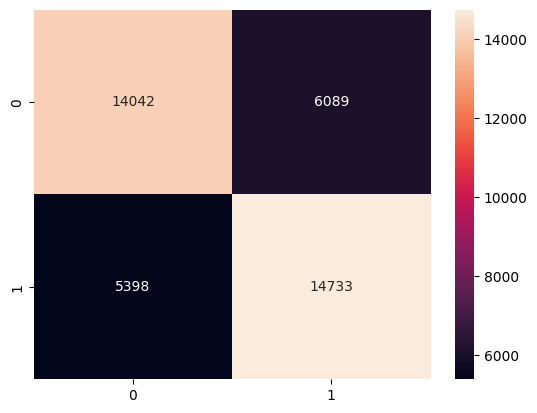

In [4]:
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

X = df_total["text"]
y= df_total["label"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

pipeline = Pipeline([
    ('w2v', Word2VecTransformer(vector_size=300, min_count=5, workers=4)),
    ('scaler', StandardScaler()), # Las redes neuronales NECESITAN escalado
    ('clf', MLPClassifier(hidden_layer_sizes=(128, 64), # Dos capas ocultas
                          activation='relu',
                          solver='adam',
                          max_iter=300, # Suele converger rápido
                          early_stopping=True, # Para evitar overfitting y ahorrar tiempo
                          random_state=42))
])

# 4. Entrenar
print("Entrenando modelo con Word2Vec...")
pipeline.fit(X_train, y_train)

# 5. Evaluar
predictions = pipeline.predict(X_test)

print("\n--- Reporte de Clasificación (Word2Vec) ---")
print(classification_report(y_test, predictions))

print("\n--- Matriz de Confusión ---")
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, predictions)
print(cm)
sns.heatmap(cm, annot=True, fmt='d')
plt.show()

 HistGradientBoostingClassifier (LightGBM nativo)


In [5]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

X = df_total["text"]
y= df_total["label"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

pipeline = Pipeline([
    ('w2v', Word2VecTransformer(vector_size=300, min_count=5, workers=4)),
    # HistGradientBoosting no requiere estrictamente escalado, pero no hace daño
    ('clf', HistGradientBoostingClassifier(max_iter=1000,
                                           learning_rate=0.1,
                                           random_state=42))
])

# 4. Entrenar
print("Entrenando modelo con Word2Vec...")
pipeline.fit(X_train, y_train)

# 5. Evaluar
predictions = pipeline.predict(X_test)

print("\n--- Reporte de Clasificación (Word2Vec) ---")
print(classification_report(y_test, predictions))

print("\n--- Matriz de Confusión ---")
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, predictions)
print(cm)
sns.heatmap

Entrenando modelo con Word2Vec...
Tokenizando datos para entrenamiento...
Entrenando modelo Word2Vec...

--- Reporte de Clasificación (Word2Vec) ---
              precision    recall  f1-score   support

           0       0.70      0.69      0.70     20131
           1       0.70      0.71      0.70     20131

    accuracy                           0.70     40262
   macro avg       0.70      0.70      0.70     40262
weighted avg       0.70      0.70      0.70     40262


--- Matriz de Confusión ---
[[13856  6275]
 [ 5802 14329]]


<function seaborn.matrix.heatmap(data, *, vmin=None, vmax=None, cmap=None, center=None, robust=False, annot=None, fmt='.2g', annot_kws=None, linewidths=0, linecolor='white', cbar=True, cbar_kws=None, cbar_ax=None, square=False, xticklabels='auto', yticklabels='auto', mask=None, ax=None, **kwargs)>

OPCIÓN 2 (Tensorflow)

Vocabulario aprendido: 108633 palabras
Forma de los datos de entrenamiento: (161048, 120)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
5033/5033 ━━━━━━━━━━━━━━━━━━━━ 84s 16ms/step - accuracy: 0.6445 - loss: 0.6224 - val_accuracy: 0.6839 - val_loss: 0.5872
Epoch 2/5
5033/5033 ━━━━━━━━━━━━━━━━━━━━ 73s 15ms/step - accuracy: 0.7239 - loss: 0.5349 - val_accuracy: 0.7191 - val_loss: 0.5294
Epoch 3/5
5033/5033 ━━━━━━━━━━━━━━━━━━━━ 83s 16ms/step - accuracy: 0.7444 - loss: 0.5011 - val_accuracy: 0.7168 - val_loss: 0.5296


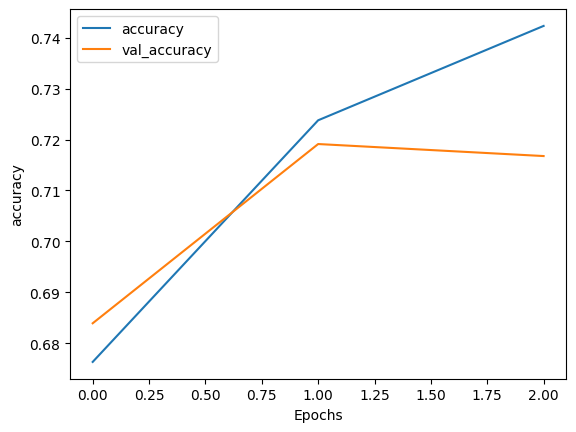

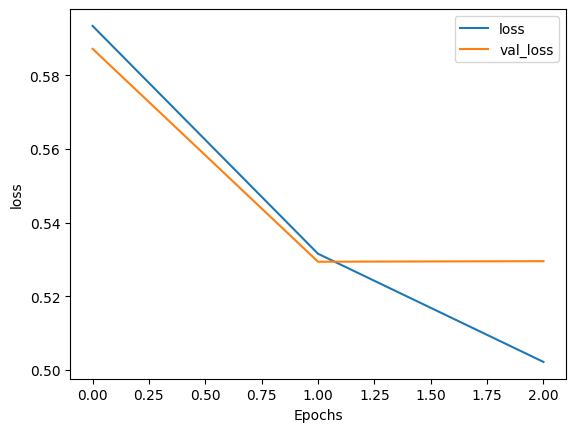

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 318ms/step

--- Predicciones ---
Texto: This product is amazing I love it very much good quality.
Probabilidad: 0.5356
Texto: Honestly, the box arrived crushed but the product inside was surprisingly intact.
Probabilidad: 0.2771
1259/1259 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step

--- Reporte de Clasificación ---
              precision    recall  f1-score   support

           0       0.74      0.69      0.71     20212
           1       0.70      0.75      0.73     20050

    accuracy                           0.72     40262
   macro avg       0.72      0.72      0.72     40262
weighted avg       0.72      0.72      0.72     40262


--- Matriz de Confusión ---
[[13921  6291]
 [ 5018 15032]]


In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Configuración de Hiperparámetros (Ajustables)
VOCAB_SIZE = 10000      # Número máximo de palabras a recordar
EMBEDDING_DIM = 16      # Dimensiones del vector de cada palabra
MAX_LENGTH = 120        # Longitud máxima de la reseña (cortará o rellenará)
TRUNC_TYPE = 'post'     # Cortar al final si es muy largo
OOV_TOK = "<OOV>"       # Token para palabras desconocidas


# 2. Separar características y etiquetas
# Asumiendo 'text_' es la reseña y 'label' es la categoría (CG/OR)
reviews = df_total['text'].astype(str).tolist()
labels_enc = df_total['label'].tolist()


# 4. Dividir en entrenamiento y prueba
train_sentences, test_sentences, train_labels, test_labels = train_test_split(
    reviews, labels_enc, test_size=0.2, random_state=42
)

# 5. Tokenización (Texto -> Números)
tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token=OOV_TOK)
tokenizer.fit_on_texts(train_sentences) # Aprender el vocabulario del train set

# Convertir a secuencias
train_sequences = tokenizer.texts_to_sequences(train_sentences)
test_sequences = tokenizer.texts_to_sequences(test_sentences)

# 6. Padding (Igualar longitudes)
# Las redes neuronales necesitan entradas de tamaño fijo
train_padded = pad_sequences(train_sequences, maxlen=MAX_LENGTH,  padding='pre',truncating=TRUNC_TYPE)
test_padded = pad_sequences(test_sequences, maxlen=MAX_LENGTH,  padding='pre', truncating=TRUNC_TYPE)

print(f"Vocabulario aprendido: {len(tokenizer.word_index)} palabras")
print(f"Forma de los datos de entrenamiento: {train_padded.shape}")

# 7. Definir el Modelo
model = tf.keras.Sequential([
    # 1. Capa de Embedding
    tf.keras.layers.Embedding(VOCAB_SIZE, EMBEDDING_DIM, input_length=MAX_LENGTH),

    # 2. Capa LSTM Bidireccional
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64)),

    # --- AQUÍ AÑADIMOS EL DROPOUT ---
    # Apagamos el 50% de las neuronas aleatoriamente para evitar memorización
    tf.keras.layers.Dropout(0.5),
    # --------------------------------

    # 3. Capa Densa Intermedia
    tf.keras.layers.Dense(24, activation='relu'),

    # 4. Salida
    tf.keras.layers.Dense(1, activation='sigmoid')
])

# Compilar
model.compile(loss='binary_crossentropy',optimizer='adam', metrics=['accuracy'])

# Resumen
model.summary()

# 9. Entrenar
#num_epochs define cuántas veces pasará el dataset completo
#puedo poner directamente epochs=3

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=1,            # si en 1 epoch no mejora, se detiene
    restore_best_weights=True
)

history = model.fit(
    train_padded,
    np.array(train_labels),
    epochs=5,             # puedes poner muchos
    validation_data=(test_padded, np.array(test_labels)),
    callbacks=[early_stop],
    verbose=1
)



import matplotlib.pyplot as plt

# 10. Gráfica de precisión
def plot_graphs(history, string):
  plt.plot(history.history[string])
  plt.plot(history.history['val_'+string])
  plt.xlabel("Epochs")
  plt.ylabel(string)
  plt.legend([string, 'val_'+string])
  plt.show()

plot_graphs(history, "accuracy")
plot_graphs(history, "loss")

# 11. Probando con una frase nueva
new_reviews = [
    "This product is amazing I love it very much good quality.", # Ejemplo 'Bot-like' simple
    "Honestly, the box arrived crushed but the product inside was surprisingly intact." # Ejemplo 'Humano'
]

# Preprocesar las nuevas frases igual que las de entrenamiento
new_sequences = tokenizer.texts_to_sequences(new_reviews)
new_padded = pad_sequences(new_sequences, maxlen=MAX_LENGTH, truncating=TRUNC_TYPE)

predictions = model.predict(new_padded)

# Decodificar resultados
print("\n--- Predicciones ---")
for i, text in enumerate(new_reviews):
    print(f"Texto: {text}")
    print(f"Probabilidad: {predictions[i][0]:.4f}")
    # Nota: Revisa cómo codificó 'encoder' tus etiquetas para saber si 1 es CG o OR.
    # Usualmente 0 es la primera clase alfabética y 1 la segunda.

from sklearn.metrics import classification_report, confusion_matrix

# 1. Obtener predicciones del modelo
y_pred_probs = model.predict(test_padded)

# 2. Convertir probabilidades a clases (0 o 1)
y_pred = (y_pred_probs > 0.5).astype(int)

# 3. Reporte de clasificación
print("\n--- Reporte de Clasificación ---")
print(classification_report(test_labels, y_pred))

# 4. Matriz de confusión
print("\n--- Matriz de Confusión ---")
print(confusion_matrix(test_labels, y_pred))

Vocabulario aprendido: 108633 palabras
Forma de los datos de entrenamiento: (161048, 150)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
1259/1259 ━━━━━━━━━━━━━━━━━━━━ 33s 21ms/step - accuracy: 0.6402 - loss: 0.6256 - val_accuracy: 0.6979 - val_loss: 0.5559
Epoch 2/5
1259/1259 ━━━━━━━━━━━━━━━━━━━━ 24s 19ms/step - accuracy: 0.7319 - loss: 0.5214 - val_accuracy: 0.7144 - val_loss: 0.5402
Epoch 3/5
1259/1259 ━━━━━━━━━━━━━━━━━━━━ 23s 19ms/step - accuracy: 0.7678 - loss: 0.4671 - val_accuracy: 0.7175 - val_loss: 0.5373
Epoch 4/5
1259/1259 ━━━━━━━━━━━━━━━━━━━━ 23s 18ms/step - accuracy: 0.7892 - loss: 0.4361 - val_accuracy: 0.6947 - val_loss: 0.5757
Epoch 5/5
1259/1259 ━━━━━━━━━━━━━━━━━━━━ 24s 19ms/step - accuracy: 0.8238 - loss: 0.3724 - val_accuracy: 0.7048 - val_loss: 0.6274


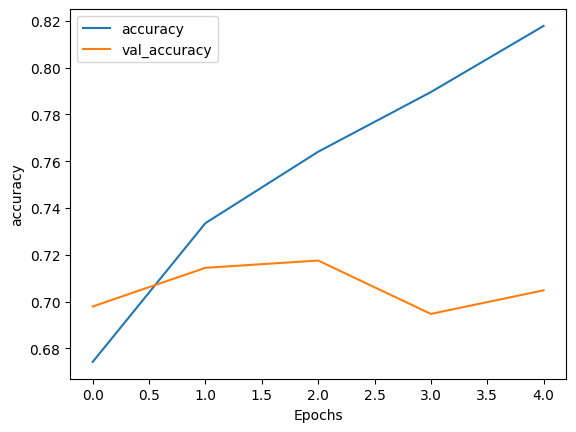

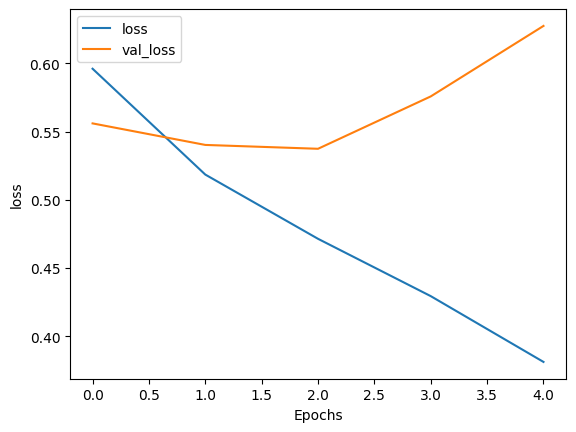

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step

--- Predicciones ---
Texto: This product is amazing I love it very much good quality.
Probabilidad: 0.4757
Texto: Honestly, the box arrived crushed but the product inside was surprisingly intact.
Probabilidad: 0.1207
1259/1259 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step

--- Reporte de Clasificación ---
              precision    recall  f1-score   support

           0       0.73      0.69      0.71     20212
           1       0.70      0.75      0.73     20050

    accuracy                           0.72     40262
   macro avg       0.72      0.72      0.72     40262
weighted avg       0.72      0.72      0.72     40262


--- Matriz de Confusión ---
[[13895  6317]
 [ 5056 14994]]


In [ ]:
#igual que antes pero otras variables para probar

import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Configuración de Hiperparámetros (Ajustables)
VOCAB_SIZE = 30000      # Número máximo de palabras a recordar
EMBEDDING_DIM = 64      # Dimensiones del vector de cada palabra
MAX_LENGTH = 150        # Longitud máxima de la reseña (cortará o rellenará)
TRUNC_TYPE = 'post'     # Cortar al final si es muy largo
OOV_TOK = "<OOV>"       # Token para palabras desconocidas


# 2. Separar características y etiquetas
# Asumiendo 'text_' es la reseña y 'label' es la categoría (CG/OR)
reviews = df_total['text'].astype(str).tolist()
labels_enc = df_total['label'].tolist()


# 4. Dividir en entrenamiento y prueba
train_sentences, test_sentences, train_labels, test_labels = train_test_split(
    reviews, labels_enc, test_size=0.2, random_state=42
)

# 5. Tokenización (Texto -> Números)
tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token=OOV_TOK)
tokenizer.fit_on_texts(train_sentences) # Aprender el vocabulario del train set

# Convertir a secuencias
train_sequences = tokenizer.texts_to_sequences(train_sentences)
test_sequences = tokenizer.texts_to_sequences(test_sentences)

# 6. Padding (Igualar longitudes)
# Las redes neuronales necesitan entradas de tamaño fijo
train_padded = pad_sequences(train_sequences, maxlen=MAX_LENGTH,  padding='pre',truncating=TRUNC_TYPE)
test_padded = pad_sequences(test_sequences, maxlen=MAX_LENGTH,  padding='pre', truncating=TRUNC_TYPE)

print(f"Vocabulario aprendido: {len(tokenizer.word_index)} palabras")
print(f"Forma de los datos de entrenamiento: {train_padded.shape}")

# 7. Definir el Modelo
model = tf.keras.Sequential([
    # 1. Capa de Embedding
    tf.keras.layers.Embedding(VOCAB_SIZE, EMBEDDING_DIM, input_length=MAX_LENGTH),

    # 2. Capa LSTM Bidireccional
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64,return_sequences=False)),

    # --- AQUÍ AÑADIMOS EL DROPOUT ---
    # Apagamos el 50% de las neuronas aleatoriamente para evitar memorización
    tf.keras.layers.Dropout(0.5),
    # --------------------------------

    # 3. Capa Densa Intermedia
    tf.keras.layers.Dense(32, activation='relu'),

    # 4. Salida
    tf.keras.layers.Dense(1, activation='sigmoid')
])

# Compilar
model.compile(loss='binary_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])

# Resumen
model.summary()

# 9. Entrenar
#num_epochs define cuántas veces pasará el dataset completo
#puedo poner directamente epochs=3

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=2,            # aumentamos para que sea más flexible
    restore_best_weights=True
)

history = model.fit(
    train_padded,
    np.array(train_labels),
    epochs=5,
    batch_size=128,
    validation_data=(test_padded, np.array(test_labels)),
    callbacks=[early_stop],
    verbose=1
)


import matplotlib.pyplot as plt

# 10. Gráfica de precisión
def plot_graphs(history, string):
  plt.plot(history.history[string])
  plt.plot(history.history['val_'+string])
  plt.xlabel("Epochs")
  plt.ylabel(string)
  plt.legend([string, 'val_'+string])
  plt.show()

plot_graphs(history, "accuracy")
plot_graphs(history, "loss")

# 11. Probando con una frase nueva
new_reviews = [
    "This product is amazing I love it very much good quality.", # Ejemplo 'Bot-like' simple
    "Honestly, the box arrived crushed but the product inside was surprisingly intact." # Ejemplo 'Humano'
]

# Preprocesar las nuevas frases igual que las de entrenamiento
new_sequences = tokenizer.texts_to_sequences(new_reviews)
new_padded = pad_sequences(new_sequences, maxlen=MAX_LENGTH, truncating=TRUNC_TYPE)

predictions = model.predict(new_padded)

# Decodificar resultados
print("\n--- Predicciones ---")
for i, text in enumerate(new_reviews):
    print(f"Texto: {text}")
    print(f"Probabilidad: {predictions[i][0]:.4f}")
    # Nota: Revisa cómo codificó 'encoder' tus etiquetas para saber si 1 es CG o OR.
    # Usualmente 0 es la primera clase alfabética y 1 la segunda.

from sklearn.metrics import classification_report, confusion_matrix

# 1. Obtener predicciones del modelo
y_pred_probs = model.predict(test_padded)

# 2. Convertir probabilidades a clases (0 o 1)
y_pred = (y_pred_probs > 0.5).astype(int)

# 3. Reporte de clasificación
print("\n--- Reporte de Clasificación ---")
print(classification_report(test_labels, y_pred))

# 4. Matriz de confusión
print("\n--- Matriz de Confusión ---")
print(confusion_matrix(test_labels, y_pred))

Train shapes -> Texto: (161048, 150), Num: (161048, 7)
Test shapes  -> Texto: (40262, 150), Num: (40262, 7)


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ entrada_texto       │ (None, 150)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 150, 64)   │  1,920,000 │ entrada_texto[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_1     │ (None, 128)       │     66,048 │ embedding_1[0][0] │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ entrada_numerica    │ (None, 7)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ bidirectional_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 16)        │        128 │ entrada_numerica… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 144)       │          0 │ dropout_1[0][0],  │
│ (Concatenate)       │                   │            │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 32)        │      4,640 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 1)         │         33 │ dense_3[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,990,849 (7.59 MB)

 Trainable params: 1,990,849 (7.59 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
1259/1259 ━━━━━━━━━━━━━━━━━━━━ 27s 19ms/step - accuracy: 0.6580 - loss: 0.6111 - val_accuracy: 0.7067 - val_loss: 0.5426
Epoch 2/10
1259/1259 ━━━━━━━━━━━━━━━━━━━━ 24s 19ms/step - accuracy: 0.7426 - loss: 0.5051 - val_accuracy: 0.7313 - val_loss: 0.5154
Epoch 3/10
1259/1259 ━━━━━━━━━━━━━━━━━━━━ 24s 19ms/step - accuracy: 0.7790 - loss: 0.4491 - val_accuracy: 0.7246 - val_loss: 0.5545
Epoch 4/10
1259/1259 ━━━━━━━━━━━━━━━━━━━━ 24s 19ms/step - accuracy: 0.8101 - loss: 0.3994 - val_accuracy: 0.7177 - val_loss: 0.5645
Epoch 5/10
1259/1259 ━━━━━━━━━━━━━━━━━━━━ 24s 19ms/step - accuracy: 0.8349 - loss: 0.3531 - val_accuracy: 0.7091 - val_loss: 0.6135
1259/1259 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step

--- Reporte de Clasificación ---
              precision    recall  f1-score   support

           0       0.76      0.68      0.72     20131
           1       0.71      0.78      0.74     20131

    accuracy                           0.73     40262
   macro avg       0.73      0.73      0.73  

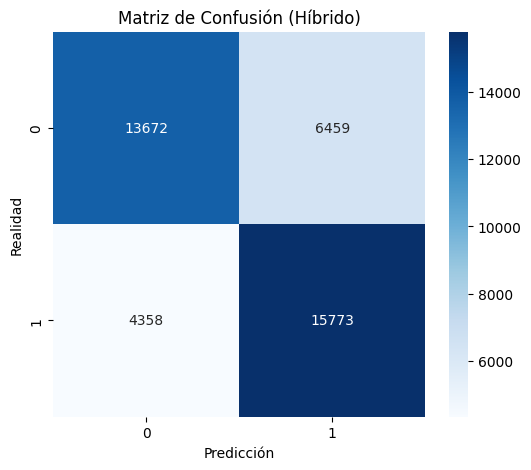

In [ ]:
#Añadimos la ingineria de caracteristica para ver si mejora
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Concatenate, Dropout, Bidirectional
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns


features_list = ['rating', 'rating_deviation', 'text_len', 'sentiment',
                 'caps_ratio', 'exclamation_count', 'lexical_diversity']
scaler = StandardScaler()
X_all_num = scaler.fit_transform(df_total[features_list])
VOCAB_SIZE = 30000
MAX_LENGTH = 150
tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(df_total['text'].astype(str))
sequences = tokenizer.texts_to_sequences(df_total['text'].astype(str))
X_all_text = pad_sequences(sequences, maxlen=MAX_LENGTH, padding='pre', truncating='post')
y_all = df_total['label'].values

X_train_text, X_test_text, X_train_num, X_test_num, y_train, y_test = train_test_split(
    X_all_text, X_all_num, y_all,
    test_size=0.2,
    random_state=42,
    stratify=y_all
)


EMBEDDING_DIM = 64

# RAMA 1: Texto
input_text = Input(shape=(MAX_LENGTH,), name='entrada_texto')
emb = Embedding(VOCAB_SIZE, EMBEDDING_DIM)(input_text)
lstm_out = Bidirectional(LSTM(64, return_sequences=False))(emb)
lstm_out = Dropout(0.5)(lstm_out)

# RAMA 2: Números
input_num = Input(shape=(len(features_list),), name='entrada_numerica')
num_out = Dense(16, activation='relu')(input_num)

# FUSIÓN
merged = Concatenate()([lstm_out, num_out])

# CLASIFICACIÓN
x = Dense(32, activation='relu')(merged)
output = Dense(1, activation='sigmoid')(x)

model_final = Model(inputs=[input_text, input_num], outputs=output)

model_final.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
model_final.summary()

# --- 4. ENTRENAMIENTO ---
from tensorflow.keras.callbacks import EarlyStopping
early = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history = model_final.fit(
    x=[X_train_text, X_train_num], # Pasamos lista de inputs
    y=y_train,
    epochs=10,
    batch_size=128,
    validation_data=([X_test_text, X_test_num], y_test),
    callbacks=[early],
    verbose=1
)

# --- 5. EVALUACIÓN Y PREDICCIONES ---
# IMPORTANTE: Al predecir, también hay que pasar los dos inputs en una lista
y_pred_probs = model_final.predict([X_test_text, X_test_num])
y_pred = (y_pred_probs > 0.5).astype(int)

print("\n--- Reporte de Clasificación ---")
print(classification_report(y_test, y_pred))

print("\n--- Matriz de Confusión ---")
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusión (Híbrido)')
plt.ylabel('Realidad')
plt.xlabel('Predicción')
plt.show()

In [ ]:
# Clasificación con LSTM + CNN (binaria)
# Aquí combinamos conv1D (para capturar patrones locales tipo n-gramas) con LSTM (para secuencia global)
import numpy as np
import pandas as pd
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional, Conv1D, MaxPooling1D
from tensorflow.keras.callbacks import EarlyStopping

VOCAB_SIZE = 30000
EMBEDDING_DIM = 64
MAX_LENGTH = 120
TRUNC_TYPE = 'post'
PADDING_TYPE = 'pre'

def preparar_datos(texts, labels, num_words=10000, max_len=120):
    tokenizer = Tokenizer(num_words=num_words, oov_token="<OOV>")
    tokenizer.fit_on_texts(texts)

    sequences = tokenizer.texts_to_sequences(texts)

    # IMPORTANTE: Usar padding y truncating iguales
    padded = pad_sequences(sequences, maxlen=max_len, padding='post', truncating='post')

    word_index = tokenizer.word_index
    # El tamaño del vocabulario es el mínimo entre tu límite y las palabras reales + 1 (por el padding 0)
    vocab_size = min(num_words, len(word_index) + 1)

    return padded, np.array(labels), tokenizer, vocab_size


texts = df_total["text"].astype(str).to_list() # .astype(str) evita errores con nulos
labels = df_total["label"].to_list()

max_len = 120
X, y, tokenizer, vocab_size = preparar_datos(texts, labels, num_words=10000, max_len=max_len)

model_hybrid = Sequential([
    # 1. Embedding
    Embedding(VOCAB_SIZE, EMBEDDING_DIM, input_length=MAX_LENGTH),

    # 2. CAPA CNN (Extractor de patrones locales)
    # filters=64: Busca 64 tipos de patrones diferentes
    # kernel_size=5: Mira ventanas de 5 palabras a la vez (5-grams)
    Conv1D(filters=64, kernel_size=5, activation='relu'),

    # 3. MAX POOLING (Reducción de dimensiones)
    # Reduce la secuencia a 1/4 de su tamaño.
    # Se queda solo con la característica más fuerte de cada grupo de 4.
    MaxPooling1D(pool_size=4),

    # 4. CAPA LSTM (Procesamiento secuencial)
    # Ahora la LSTM recibe una secuencia más corta y densa en información.
    # Usamos Bidirectional para que lea en ambos sentidos.
    Bidirectional(LSTM(64)), # No necesitamos return_sequences=True porque es la última recurrente

    # 5. Dropout y Clasificación
    Dropout(0.5), # Regularización fuerte
    Dense(1, activation='sigmoid')
])

# Compilar
model_hybrid.compile(loss='binary_crossentropy',
                     optimizer='adam',
                     metrics=['accuracy'])

model_hybrid.summary()

# --- ENTRENAMIENTO ---
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3, # Un poco más de paciencia
    restore_best_weights=True
)

history_hybrid = model_hybrid.fit(
    train_padded,
    np.array(train_labels),
    epochs=10, # Las CNN convergen rápido, quizás en 4-5 épocas esté listo
    validation_data=(test_padded, np.array(test_labels)),
    callbacks=[early_stop],
    verbose=1
)

# --- EVALUACIÓN ---
from sklearn.metrics import classification_report, confusion_matrix

print("\n--- Evaluando Modelo Híbrido CNN-LSTM ---")
y_pred_probs = model_hybrid.predict(test_padded)
y_pred = (y_pred_probs > 0.5).astype(int)

print(classification_report(test_labels, y_pred))
print(confusion_matrix(test_labels, y_pred))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
5033/5033 ━━━━━━━━━━━━━━━━━━━━ 61s 11ms/step - accuracy: 0.6641 - loss: 0.6059 - val_accuracy: 0.7104 - val_loss: 0.5397
Epoch 2/10
5033/5033 ━━━━━━━━━━━━━━━━━━━━ 58s 12ms/step - accuracy: 0.7389 - loss: 0.5070 - val_accuracy: 0.7110 - val_loss: 0.5380
Epoch 3/10
5033/5033 ━━━━━━━━━━━━━━━━━━━━ 59s 12ms/step - accuracy: 0.7707 - loss: 0.4582 - val_accuracy: 0.7195 - val_loss: 0.5495
Epoch 4/10
5033/5033 ━━━━━━━━━━━━━━━━━━━━ 79s 11ms/step - accuracy: 0.8133 - loss: 0.3957 - val_accuracy: 0.7098 - val_loss: 0.5763
Epoch 5/10
5033/5033 ━━━━━━━━━━━━━━━━━━━━ 55s 11ms/step - accuracy: 0.8570 - loss: 0.3176 - val_accuracy: 0.6987 - val_loss: 0.6980

--- Evaluando Modelo Híbrido CNN-LSTM ---
1259/1259 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step
              precision    recall  f1-score   support

           0       0.78      0.60      0.67     20212
           1       0.67      0.83      0.74     20050

    accuracy                           0.71     40262
   macro avg       0.72      0.71   

Datos Texto Train: (161048, 120)
Datos Num Train: (161048, 6)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_text          │ (None, 120)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 120, 64)   │  1,920,000 │ input_text[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 116, 32)   │     10,272 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 29, 32)    │          0 │ conv1d[0][0]      │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_num           │ (None, 6)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 64)        │     16,640 │ max_pooling1d[0]… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 16)        │        112 │ input_num[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 16)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 80)        │          0 │ dropout[0][0],    │
│ (Concatenate)       │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 16)        │      1,296 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │         17 │ dense_1[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,948,337 (7.43 MB)

 Trainable params: 1,948,337 (7.43 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
1259/1259 ━━━━━━━━━━━━━━━━━━━━ 33s 20ms/step - accuracy: 0.6434 - loss: 0.8321 - val_accuracy: 0.7142 - val_loss: 0.5495
Epoch 2/10
1259/1259 ━━━━━━━━━━━━━━━━━━━━ 27s 12ms/step - accuracy: 0.7346 - loss: 0.5263 - val_accuracy: 0.7145 - val_loss: 0.5438
Epoch 3/10
1259/1259 ━━━━━━━━━━━━━━━━━━━━ 16s 12ms/step - accuracy: 0.7778 - loss: 0.4642 - val_accuracy: 0.7123 - val_loss: 0.5609
Epoch 4/10
1259/1259 ━━━━━━━━━━━━━━━━━━━━ 18s 14ms/step - accuracy: 0.8371 - loss: 0.3669 - val_accuracy: 0.6947 - val_loss: 0.6357
Epoch 5/10
1259/1259 ━━━━━━━━━━━━━━━━━━━━ 16s 13ms/step - accuracy: 0.8958 - loss: 0.2593 - val_accuracy: 0.6699 - val_loss: 0.9469

--- Evaluando Modelo Híbrido ---
1259/1259 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step
              precision    recall  f1-score   support

           0       0.77      0.62      0.68     20131
           1       0.68      0.81      0.74     20131

    accuracy                           0.71     40262
   macro avg       0.72      0.71      0.71  

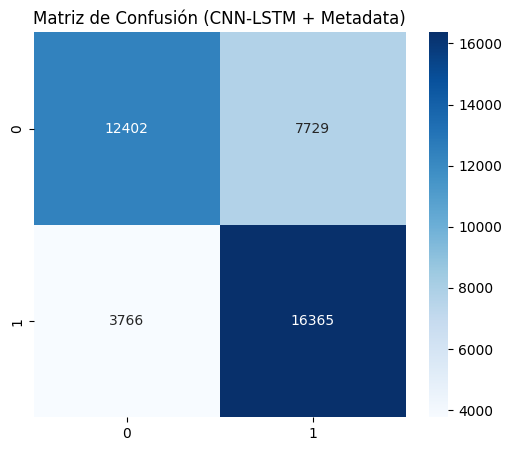

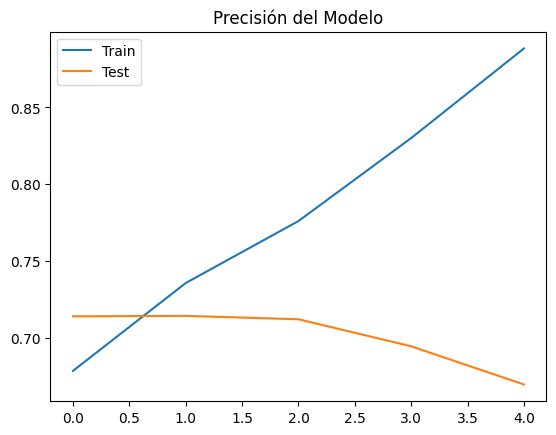

In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout, Bidirectional, Conv1D, MaxPooling1D, Concatenate
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from textblob import TextBlob
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.regularizers import l2
#con ingienria caracteristicas
features_list = ['rating', 'rating_deviation', 'text_len', 'sentiment', 'caps_ratio', 'exclamation_count']
df_total[features_list] = df_total[features_list].fillna(0)

# --- 2. PREPARACIÓN DE DATOS (TEXTO + NÚMEROS) ---

# Configuración
VOCAB_SIZE = 30000
EMBEDDING_DIM = 64
MAX_LENGTH = 120
PADDING_TYPE = 'pre'
TRUNC_TYPE = 'post'

# A) Escalar Números (Vital para redes neuronales)
scaler = StandardScaler()
X_all_num = scaler.fit_transform(df_total[features_list])

# B) Tokenizar Texto
tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(df_total['text'])
sequences = tokenizer.texts_to_sequences(df_total['text'])
X_all_text = pad_sequences(sequences, maxlen=MAX_LENGTH, padding=PADDING_TYPE, truncating=TRUNC_TYPE)

# C) Etiquetas
y_all = df_total['label'].values

# --- 3. SPLIT ALINEADO ---
# Dividimos todo junto para que la fila de texto coincida con la de números
X_train_text, X_test_text, X_train_num, X_test_num, y_train, y_test = train_test_split(
    X_all_text, X_all_num, y_all,
    test_size=0.2,
    random_state=42,
    stratify=y_all
)

print(f"Datos Texto Train: {X_train_text.shape}")
print(f"Datos Num Train: {X_train_num.shape}")

# --- 4. ARQUITECTURA HÍBRIDA (CNN-LSTM + METADATA) ---

# RAMA 1: Procesamiento de Texto (Tu arquitectura CNN-LSTM)
input_text = Input(shape=(MAX_LENGTH,), name='input_text')
emb = Embedding(VOCAB_SIZE, EMBEDDING_DIM)(input_text)

# Capa CNN para patrones locales (n-gramas)
x1 = Conv1D(filters=32, kernel_size=5, activation='relu')(emb)
x1 = MaxPooling1D(pool_size=4)(x1) # Reduce longitud a 1/4 (30 pasos)

# LSTM: Bajamos de 64 a 32 unidades y añadimos regularización L2
# kernel_regularizer=l2(0.01) impide que los pesos crezcan mucho (evita memorización)
x1 = Bidirectional(LSTM(32, kernel_regularizer=l2(0.01)))(x1)
x1 = Dropout(0.6)(x1) # Subimos Dropout a 60% (es muy agresivo, pero necesario aquí)

# RAMA 2: Números
input_num = Input(shape=(len(features_list),), name='input_num')
# También reducimos y regularizamos esta capa
x2 = Dense(16, activation='relu', kernel_regularizer=l2(0.01))(input_num)
x2 = Dropout(0.3)(x2) # Añadimos dropout también a los números

# FUSIÓN: Juntamos lo que vio la CNN-LSTM con los datos estadísticos
merged = Concatenate()([x1, x2])

# CLASIFICACIÓN FINAL
dense_final = Dense(16, activation='relu')(merged)
output = Dense(1, activation='sigmoid')(dense_final)

# Crear Modelo
model_hybrid = Model(inputs=[input_text, input_num], outputs=output)

model_hybrid.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
model_hybrid.summary()

# --- 5. ENTRENAMIENTO ---
from tensorflow.keras.callbacks import EarlyStopping
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history = model_hybrid.fit(
    x=[X_train_text, X_train_num], # <--- LISTA DE DOS INPUTS
    y=y_train,
    epochs=10,
    batch_size=128,
    validation_data=([X_test_text, X_test_num], y_test),
    callbacks=[early_stop],
    verbose=1
)

# --- 6. EVALUACIÓN ---
print("\n--- Evaluando Modelo Híbrido ---")
# Predecir pasando ambos inputs
y_pred_probs = model_hybrid.predict([X_test_text, X_test_num])
y_pred = (y_pred_probs > 0.5).astype(int)

print(classification_report(y_test, y_pred))

plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusión (CNN-LSTM + Metadata)')
plt.show()

# Gráfica de aprendizaje
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Test')
plt.title('Precisión del Modelo')
plt.legend()
plt.show()